<a href="https://colab.research.google.com/github/v01dcrush/42hitshard/blob/main/cuda_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install nvcc
!pip install nvcc4jupyter

In [2]:
#load plugin
%load_ext nvcc4jupyter

Detected platform "Colab". Running its setup...
Source files will be saved in "/tmp/tmpwizj0piw".


In [3]:
#install opencv for imread/imwrite
!apt-get update -y
!apt-get install -y --fix-missing libopencv-dev pkg-config


Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 http://archive.ubuntu.com/ubuntu noble InRelease
Get:3 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:4 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:5 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:6 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:7 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:8 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:9 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:10 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [78.0 kB]
Get:11 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:12 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,111 kB]
Get:13 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x8

In [4]:
#download image
import urllib.request

# Download a sample test image
url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"
url = "https://github.com/opencv/opencv/blob/5.x/samples/data/apple.jpg?raw=true"
input_image = "input.jpg"
urllib.request.urlretrieve(url, input_image)
print("Downloaded input.jpg successfully!")

Downloaded input.jpg successfully!


In [29]:
%%writefile kernel.cu

#include <iostream>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

__constant__ float w[3][3] = {{1.0f, 2.0f, 1.0f},{2.0f, 4.0f, 2.0f},{1.0f, 2.0f, 1.0f}};

// Custom CUDA Kernel: Derives the picture
__global__ void DerivKernel(const uchar4* d_input, uchar4* d_output, int width, int height) {
  int blockStartX = blockIdx.x*(blockDim.x-2);
  int blockStartY = blockIdx.y*(blockDim.y-2);
  int offsetX = blockStartX - 1 + threadIdx.x;
  int offsetY = blockStartY - 1 + threadIdx.y;
  if(offsetX > width || offsetY > height){
    return;
  }
  int x = ::min(::max(0, offsetX), width-1);
  int y = ::min(::max(0, offsetY), height-1);
  uchar4 px = d_input[y*width+x];
  __shared__ uchar4 cache[32][32];
  cache[threadIdx.y][threadIdx.x] = px;
  __syncthreads();
  if(threadIdx.x>29 || threadIdx.y>29){
    return;
  }
  float4 outp;
  outp.x = 0.0f;
  outp.y = 0.0f;
  outp.z = 0.0f;
  outp.w = 255.0f;
  uchar4 temp1;
  #pragma unroll
  for(int i=-1; i<2; i++){
    #pragma unroll
    for(int j=-1; j<2; j++){
      uchar4 temp = cache[threadIdx.y+1+i][threadIdx.x+1+j];
      outp.x += temp.x*w[i+1][j+1];
      outp.y += temp.y*w[i+1][j+1];
      outp.z += temp.z*w[i+1][j+1];
    }
  }
  temp1.x = outp.x/16;
  temp1.y = outp.y/16;
  temp1.z = outp.z/16;
  temp1.w = outp.w/16;
  int ind;
  ind = (blockStartY+threadIdx.y)*width+(blockStartX+threadIdx.x);
  d_output[ind] = temp1;
}

int main() {
    // 1. Read input image with OpenCV
    cv::Mat h_img = cv::imread("input.jpg", cv::IMREAD_COLOR);
    if (h_img.empty()) {
        std::cerr << "Failed to load input.jpg\n";
        return -1;
    }
    if (4 != h_img.channels()) {
      cv::cvtColor(h_img, h_img, cv::COLOR_BGR2BGRA);
    }

    int width = h_img.cols;
    int height = h_img.rows;

    // 2. Allocate GPU Memory
    uchar4 *d_input, *d_output;
    cudaMalloc(&d_input, width*height*4);
    cudaMalloc(&d_output, width*height*4);

    // 3. Copy host data to GPU
    cudaMemcpy(d_input, h_img.data, width*height*4, cudaMemcpyHostToDevice);

    // 4. Launch CUDA Kernel
    dim3 block(32, 32);
    dim3 grid((width+30-1)/30, (height+30-1)/30);

    DerivKernel<<<grid, block>>>(d_input, d_output, width, height);
    cudaDeviceSynchronize();

    // 5. Copy result back to CPU Memory
    cv::Mat h_4(height, width, CV_8UC4);
    cudaMemcpy(h_4.data, d_output, width*height*4, cudaMemcpyDeviceToHost);

    // 6. Save image to disk
    cv::imwrite("output_gray.jpg", h_4);
    std::cout << "CUDA kernel executed successfully! Output saved to output_gray.jpg\n";

    // Clean up GPU memory
    cudaFree(d_input);
    cudaFree(d_output);

    return 0;
}

Overwriting kernel.cu


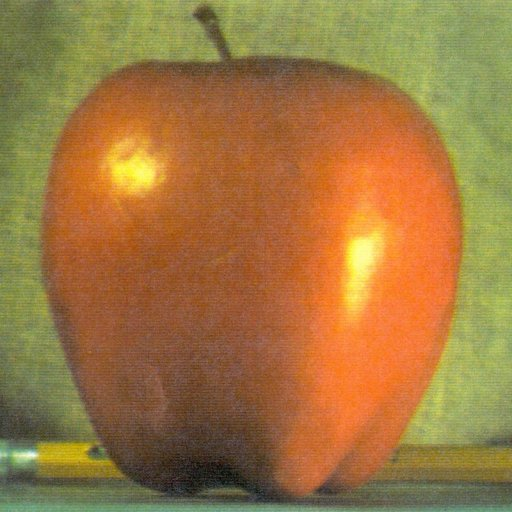

CUDA kernel executed successfully! Output saved to output_gray.jpg


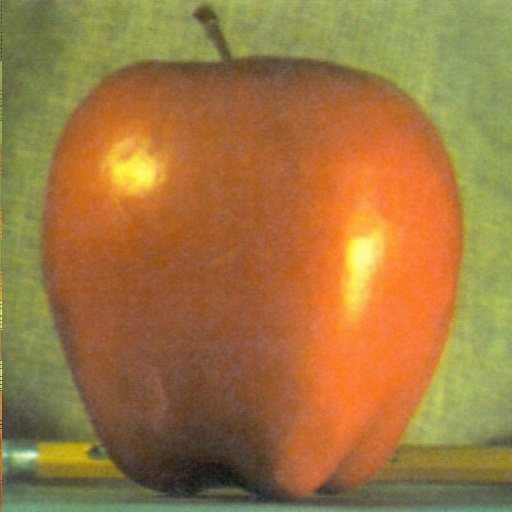

In [30]:
from IPython.display import display, Image
display(Image("input.jpg", width=300))

# Compile kernel.cu with OpenCV flags trailing at the end
!nvcc kernel.cu -o app \
  -I/usr/include/opencv4 \
  -Wno-deprecated-gpu-targets \
  -Xcudafe "--diag_suppress=611" \
  `pkg-config --libs opencv4`

# Run binary
!./app

# Render output
from IPython.display import display, Image
display(Image("output_gray.jpg", width=300))